In [1]:
%%HTML
<link rel="stylesheet" href="../custom.css"/>

# More Gravity Methods
--------------

Today's Goals:
* Gravity Gradient
* Time-Lapse Gravity
* Density Logging

## Let's go back to submarines....
![canyon](resources/submarinecanyon.jpg)

**A story:**
* In the 1970s we needed to move submarines quietly and armed with ballistics...
* Pinging.... like turning on a floodlight to adversaries or lighting a flare
* Can't work with gyroscopes (like the first on-board car navigation system Honda Electro Gyrocator... pre-GPS!) because gyroscopes **drift** and we can't come to the surface to correct for it without showing everyone where we are


![hondanav](resources/Electro_Gyrocator.jpg)
![gyroscope](resources/Gas_gyroscope.jpg)

**So what do we do?**


## Remember Gterrain?
Bit annoying that mountains pull on you, but what if we can use that to our advantage?
What if we used fundamental gravitational concepts like 
* a) the fact that gravity falls off at a rate of 1/r^2 and
* b) the force of gravity is directly (linearly proportional) to the sumation of masses
to navigate the underwater world in the dark and in total silence?

How do we combine these two ideas? What is it called when you measure the rate of change of something?

# Gravity Gradient

## The oldest method of measuring gravity
<div class="row">
<div class="column">

* Torsion balance (circa Cavendish 1798)
    * Hang two masses on a balanced beam, measure the rotation of beam.
* Modern:
    * Spinning accelerometers
    * Measured from a moving platform!
![cubs](resources/11-gg_accel.png)
</div>
<div class="column">


![cubs](resources/11-gg-torsion.png)
</div>
</div>

## A small bit of theory
* Often in gravity we measure a single component (the vertical component)
* There are other components too!
* Gravity gradient is the spatial rate of change of each component of the gravity vector -> Tensor
$$ \vec{g}(\vec{r}_{obs}) = - \gamma m \frac{\vec{\Delta r}}{|\vec{\Delta r}|^3} \text{,}\hspace{20pt} \vec{\Delta r} = \vec{r}_{obs} - \vec{r}_{mass} $$
$$ GG(\vec{r}_{obs}) = \nabla \vec{g}^T(\vec{r}_{obs})$$
$$ GG(\vec{r}_{obs}) = -\gamma m \left( \frac{I_{3 \times 3}}{|\vec{\Delta r}|^3}  - 3 \frac{ \vec{\Delta r} \vec{\Delta r}^T}{|\vec{\Delta r}^5}\right)$$


## What does it look like?

In [2]:
import matplotlib.pyplot as plt
import geoana.gravity as grav
import numpy as np

In [3]:
x,y,z = np.mgrid[-100:100:256j,-100:100:256j, 0:1:1j].squeeze()
xyz = np.stack([x, y, z], axis=-1)

In [4]:
def make_grav_plot():
    source = grav.PointMass(mass=1E5, location=[0, 0, 25])
    gv = source.gravitational_field(xyz) * 1E8

    vabs = np.abs(gv).max()
    cmap = 'seismic'
    pcolor_kwargs = dict(cmap='seismic', vmin=-vabs, vmax=vabs)

    fig, axes = plt.subplots(1, 3, figsize=(10,4))
    ax = axes[0]
    ax.pcolormesh(x, y, gv[...,1].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_ylabel('Northing (m)')
    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_N$')

    
    ax = axes[1]
    ax.pcolormesh(x, y, gv[...,0].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_yticklabels([])
    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_E$')

    ax = axes[2]
    im = ax.pcolormesh(x, y, gv[...,2].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_yticklabels([])
    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_D$')
    
    cb = plt.colorbar(im, ax=axes, shrink=0.7)
    cb.set_label(r'$\mu$Gal')

### Consider gravity from a point:

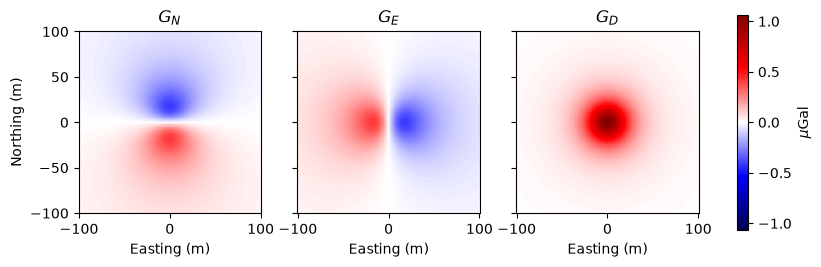

In [5]:
make_grav_plot()

In [8]:
def make_gg_plot():
    source = grav.PointMass(mass=1E5, location=[0, 0, -25])
    gg = source.gravitational_gradient(xyz) * 1E8

    vabs = np.abs(gg).max()
    cmap = 'seismic'
    pcolor_kwargs = dict(cmap='seismic', levels=np.linspace(-vabs,vabs,51))

    fig, axes = plt.subplots(3, 3, figsize=(10,10))
    ax = axes[0, 0]
    ax.contourf(x, y, gg[..., 1, 1].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_ylabel('Northing (m)')
    ax.set_title(r'$G_{NN}$')
    
    ax = axes[0, 1]
    ax.contourf(x, y, gg[..., 1, 0].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_title(r'$G_{NE}$')
    
    ax = axes[1, 0]
    ax.contourf(x, y, gg[..., 0, 1].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_ylabel('Northing (m)')
    ax.set_title(r'$G_{EN}$')
    
    ax = axes[0, 2]
    ax.contourf(x, y, -gg[..., 1, 2].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_title(r'$G_{NZ}$')
    
    ax = axes[2, 0]
    ax.contourf(x, y, -gg[..., 2, 1].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_ylabel('Northing (m)')
    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_{ZN}$')
    
    ax = axes[1, 1]
    ax.contourf(x, y, gg[...,0, 0].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_yticklabels([])
    ax.set_title(r'$G_{EE}$')
    
    ax = axes[1, 2]
    ax.contourf(x, y, -gg[..., 0, 2].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_title(r'$G_{EZ}$')
    
    ax = axes[2, 1]
    ax.contourf(x, y, -gg[..., 2, 0].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_ylabel('Northing (m)')
    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_{EZ}$')

    ax = axes[2, 2]
    im = ax.contourf(x, y, gg[...,2, 2].reshape(x.shape), **pcolor_kwargs)
    ax.set_aspect(1)
    ax.set_yticklabels([])

    ax.set_xlabel('Easting (m)')
    ax.set_title(r'$G_{DD}$')
    
    cb = plt.colorbar(im, ax=axes, shrink=0.7)
    cb.set_label(r'$\mu$Gal')

### Gravity gradient looks like:

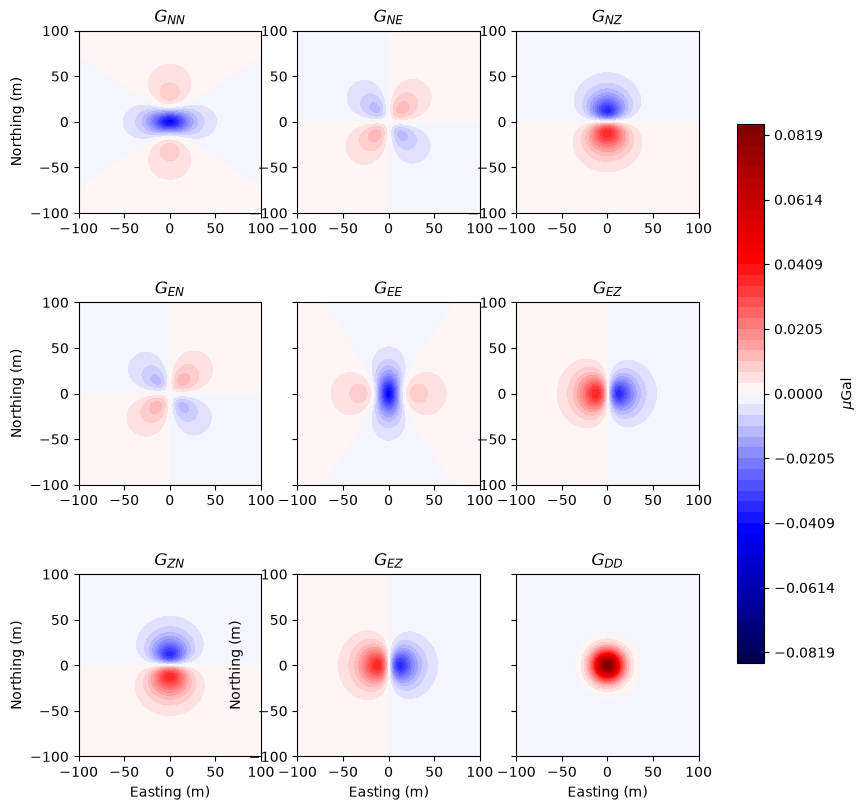

In [9]:
make_gg_plot()

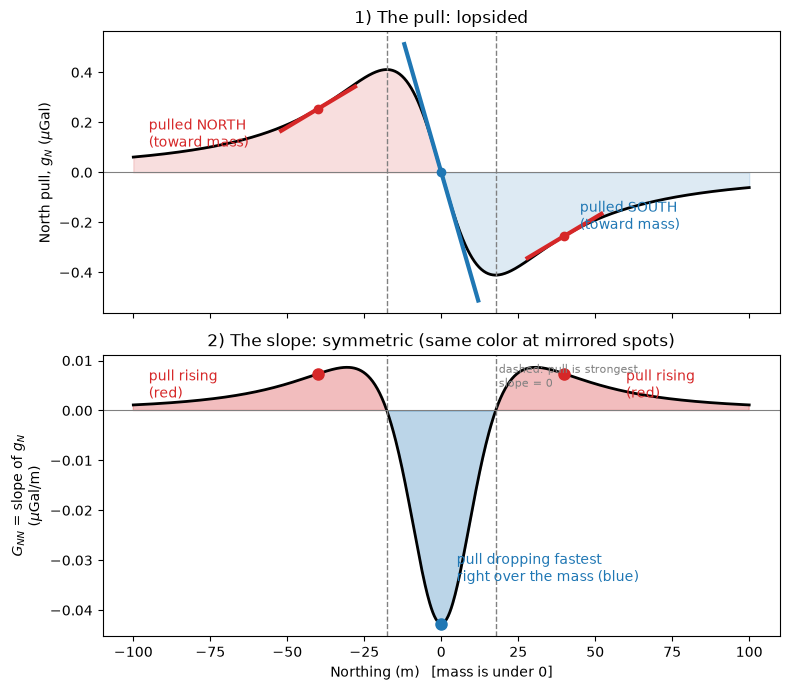

In [10]:
import numpy as np
import matplotlib.pyplot as plt

gamma = 6.674e-11   # gravitational constant
m = 1e5             # mass (kg), same as the lecture demo
h = 25.0            # depth of the point mass (m)

# Profile along the north-south line straight over the mass
y = np.linspace(-100, 100, 801)                      # northing (m)
r = np.sqrt(y**2 + h**2)
gN = -gamma * m * y / r**3 * 1e8                     # north pull (uGal), + = pulled north
GNN = -gamma * m * (r**2 - 3 * y**2) / r**5 * 1e8    # slope of gN going north (uGal/m)
ypk = h / np.sqrt(2)                                 # where the pull is strongest

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# Top: the pull itself
ax = axes[0]
ax.plot(y, gN, 'k', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.fill_between(y, gN, 0, where=gN > 0, color='tab:red', alpha=0.15)
ax.fill_between(y, gN, 0, where=gN < 0, color='tab:blue', alpha=0.15)
ax.set_ylabel('North pull, $g_N$ ($\\mu$Gal)')
ax.set_title('1) The pull: lopsided')
ax.text(-95, 0.25 * gN.max(), 'pulled NORTH\n(toward mass)', color='tab:red')
ax.text(45, 0.55 * gN.min(), 'pulled SOUTH\n(toward mass)', color='tab:blue')

# Tangent lines show the slope at three spots (this slope is what G_NN maps)
for y0, col in [(-40, 'tab:red'), (0, 'tab:blue'), (40, 'tab:red')]:
    i = np.argmin(abs(y - y0))
    seg = np.linspace(y0 - 12, y0 + 12, 2)
    ax.plot(seg, gN[i] + GNN[i] * (seg - y0), color=col, lw=3)
    ax.plot(y0, gN[i], 'o', color=col)
for s in (-1, 1):
    ax.axvline(s * ypk, color='gray', ls='--', lw=1)

# Bottom: the slope of the pull
ax = axes[1]
ax.plot(y, GNN, 'k', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.fill_between(y, GNN, 0, where=GNN > 0, color='tab:red', alpha=0.3)
ax.fill_between(y, GNN, 0, where=GNN < 0, color='tab:blue', alpha=0.3)
for y0, col in [(-40, 'tab:red'), (0, 'tab:blue'), (40, 'tab:red')]:
    i = np.argmin(abs(y - y0))
    ax.plot(y0, GNN[i], 'o', color=col, ms=8)
for s in (-1, 1):
    ax.axvline(s * ypk, color='gray', ls='--', lw=1)
ax.set_ylabel('$G_{NN}$ = slope of $g_N$\n($\\mu$Gal/m)')
ax.set_xlabel('Northing (m)   [mass is under 0]')
ax.set_title('2) The slope: symmetric (same color at mirrored spots)')
ax.text(-95, 0.3 * GNN.max(), 'pull rising\n(red)', color='tab:red')
ax.text(60, 0.3 * GNN.max(), 'pull rising\n(red)', color='tab:red')
ax.text(5, 0.8 * GNN.min(), 'pull dropping fastest\nright over the mass (blue)', color='tab:blue')
ax.text(ypk + 1, 0.55 * GNN.max(), 'dashed: pull is strongest,\nslope = 0', fontsize=8, color='gray')

plt.tight_layout()
plt.show()

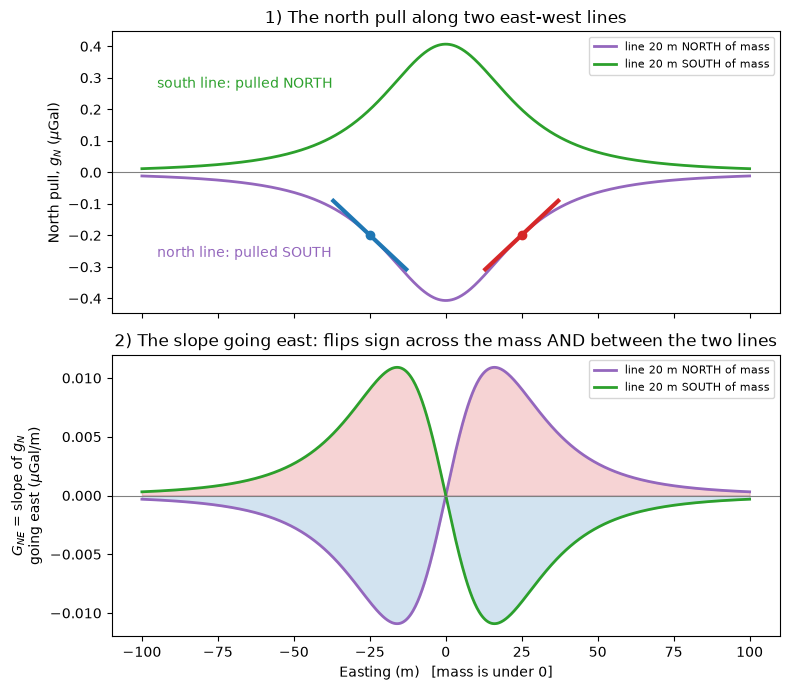

In [12]:
import numpy as np
import matplotlib.pyplot as plt

gamma, m, h = 6.674e-11, 1e5, 25.0   # constant, mass (kg), depth (m)
x = np.linspace(-100, 100, 801)       # easting (m)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
lines = [(20, 'tab:purple', 'line 20 m NORTH of mass'),
         (-20, 'tab:green', 'line 20 m SOUTH of mass')]

for yl, col, lab in lines:
    r = np.sqrt(x**2 + yl**2 + h**2)
    gN = -gamma * m * yl / r**3 * 1e8          # north pull (uGal), + = pulled north
    GNE = 3 * gamma * m * x * yl / r**5 * 1e8  # slope of gN going east (uGal/m)

    axes[0].plot(x, gN, color=col, lw=2, label=lab)
    axes[1].plot(x, GNE, color=col, lw=2, label=lab)
    axes[1].fill_between(x, GNE, 0, where=GNE > 0, color='tab:red', alpha=0.2)
    axes[1].fill_between(x, GNE, 0, where=GNE < 0, color='tab:blue', alpha=0.2)

    # tangent lines on the north line only, to show the slope
    if yl > 0:
        for x0, tcol in [(-25, 'tab:blue'), (25, 'tab:red')]:
            i = np.argmin(abs(x - x0))
            seg = np.linspace(x0 - 12, x0 + 12, 2)
            axes[0].plot(seg, gN[i] + GNE[i] * (seg - x0), color=tcol, lw=3)
            axes[0].plot(x0, gN[i], 'o', color=tcol)

ax = axes[0]
ax.axhline(0, color='gray', lw=0.8)
ax.set_ylabel('North pull, $g_N$ ($\\mu$Gal)')
ax.set_title('1) The north pull along two east-west lines')
ax.text(-95, 0.6 * ax.get_ylim()[1], 'south line: pulled NORTH', color='tab:green')
ax.text(-95, 0.6 * ax.get_ylim()[0], 'north line: pulled SOUTH', color='tab:purple')
ax.legend(loc='upper right', fontsize=8)

ax = axes[1]
ax.axhline(0, color='gray', lw=0.8)
ax.set_ylabel('$G_{NE}$ = slope of $g_N$\ngoing east ($\\mu$Gal/m)')
ax.set_xlabel('Easting (m)   [mass is under 0]')
ax.set_title('2) The slope going east: flips sign across the mass AND between the two lines')
ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

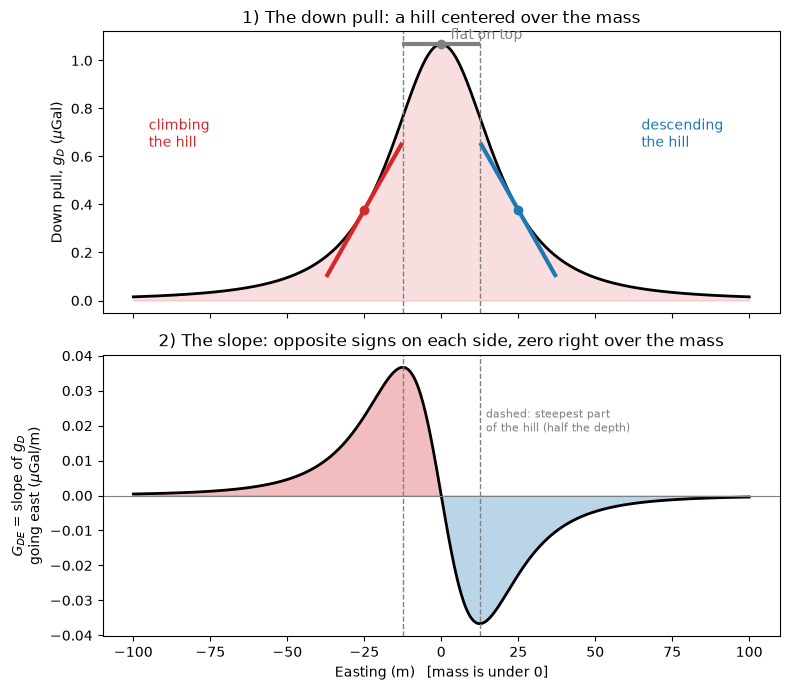

In [17]:
import numpy as np
import matplotlib.pyplot as plt

gamma, m, h = 6.674e-11, 1e5, 25.0
x = np.linspace(-100, 100, 801)
r = np.sqrt(x**2 + h**2)
gD = gamma * m * h / r**3 * 1e8                 # down pull (uGal), + = pulled down
GDE = -3 * gamma * m * h * x / r**5 * 1e8       # slope of gD going east (uGal/m)
xs = h / 2                                      # steepest points of the hill

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax = axes[0]
ax.plot(x, gD, 'k', lw=2)
ax.fill_between(x, gD, 0, color='tab:red', alpha=0.15)
for x0, col in [(-25, 'tab:red'), (0, 'gray'), (25, 'tab:blue')]:
    i = np.argmin(abs(x - x0))
    seg = np.linspace(x0 - 12, x0 + 12, 2)
    ax.plot(seg, gD[i] + GDE[i] * (seg - x0), color=col, lw=3)
    ax.plot(x0, gD[i], 'o', color=col)
for s in (-1, 1):
    ax.axvline(s * xs, color='gray', ls='--', lw=1)
ax.set_ylabel('Down pull, $g_D$ ($\\mu$Gal)')
ax.set_title('1) The down pull: a hill centered over the mass')
ax.text(-95, 0.6 * gD.max(), 'climbing\nthe hill', color='tab:red')
ax.text(65, 0.6 * gD.max(), 'descending\nthe hill', color='tab:blue')
ax.text(3, 1.02 * gD.max(), 'flat on top', color='gray')

ax = axes[1]
ax.plot(x, GDE, 'k', lw=2)
ax.axhline(0, color='gray', lw=0.8)
ax.fill_between(x, GDE, 0, where=GDE > 0, color='tab:red', alpha=0.3)
ax.fill_between(x, GDE, 0, where=GDE < 0, color='tab:blue', alpha=0.3)
for s in (-1, 1):
    ax.axvline(s * xs, color='gray', ls='--', lw=1)
ax.set_ylabel('$G_{DE}$ = slope of $g_D$\ngoing east ($\\mu$Gal/m)')
ax.set_xlabel('Easting (m)   [mass is under 0]')
ax.set_title('2) The slope: opposite signs on each side, zero right over the mass')
ax.text(xs + 2, 0.5 * GDE.max(), 'dashed: steepest part\nof the hill (half the depth)', fontsize=8, color='gray')

plt.tight_layout()
plt.show()

### Gravity Gradient
* Each observation is a component of a tensor!
$$
\begin{pmatrix}
G_{xx} & G_{xy} & G_{xz}\\
G_{yx} & G_{yy} & G_{yz}\\
G_{zx} & G_{zy} & G_{zz}
\end{pmatrix}
$$

* That tensor is symmetric:
$$ G_{ij} = G_{ji}$$
* Also has zero-trace.... why?
$$ G_{xx} + G_{yy} + G_{zz} = 0 $$

## Units?
* Gravity (an acceleration) (m/s^2) -> 10E5 mGal
* GG, rate of spatial change of gravity
    * 1 Eotvos = 10E-9 (1/s^2)
    * 1Eo = 1E-4 (mGal/m)
    * 1Eo = 0.1 (mGal/km) = (0.1 µGal/m)
    * 1Eo = (1E-3 µGal/cm)
* Current instrument sensitivity ~ 1-2 Eotvos

### Interpreting GG data:
Usually through inversion.
<div class="row">
<div class="column">

GG Data
![gg-data](resources/11-gg-dat.png)
Can you see any features that look like point anomalies?
</div>
<div class="column">

GG Inversion
![inversion](resources/11-gg-interp.png)
</div>
</div>
(Martinez et. al. 2012)

# Time-lapse Gravity

### Consider
Which gravity corrections are (relatively) not time dependent?

* Latitude
* Terrain
* Free-air
* Isostatic

What happens if we take a gravity measurement at the same location two times over a long time period (years apart)?

## Time-lapse gravity
$$ \Delta g = g_{obs, 2} - g_{obs, 1}$$
$$\Delta g = g_{anomaly, 2} + g_{drift, 2} + g_{lat} + g_{free_air} + g_{terrain}... - (g_{obs, 1} + g_{drift, 1} + g_{lat} + g_{free_air} + ...) $$
$$\Delta g  = g_{anomaly, 2} - g_{anomaly, 1} + (drift)$$


## But what is the change in gravity related to?
What can change in this equation in time?
$$ \vec{g}(\vec{r}_{obs}) = - \gamma \int_{V} \rho(\vec{r'}) \frac{\vec{\Delta r}}{|\vec{\Delta r}|^3} dV' $$

* Sensitive to changes in mass distribution over time!

### Leyden Mine:
<div class="row">
<div class="column">


![LeydenCross](resources/10-Leyden-Cross.png)

</div>
<div class="column">
    
![LeydenExtent](resources/10-Leyden-extent.png)
</div>
</div>

# Density Determination


# A quick note on density logging
Density information is used in:
* Reducing observed data (Terrain correction)
* Forward modeling (As a necessity)
* Inversion (prior information)
* Interpretation (to correlate with geology)

How can we determine absolute density?
* Direct sampling (surface and drill cores)
* Gamma ray logging
* Borehole gravity
* etc.


# Density Logs:
From a borehole gravimeter:

![density log](resources/11-density-log.png)

## Gamma-ray Logging
![gamma log](resources/11-gamma-log.png)

# Gravity Finito!

# Lab on Tuesday!

We are going underground beneath MINES tomorrow! You will measure the depth and geometry of the two tunnels that we seek to detect with Gravity two weeks later. The tunnel will be tight and warm.

* Meet: at the GP equipment room (Brian's lab) by 1pm.  Please do not be late!!!!!
* You have to protect your body:
    * hard hats
    * closed toe shoes
    * pants
    * long sleeves
* If you do not bring your own hard hat, we will provide it for you.